# Selección de modelo de clasificación — UniBank

## Propósito

Comparar **tres clasificadores** para predecir `Subscription`. La métrica de la competencia es ROC-AUC; por eso esa será la métrica principal para ordenar los candidatos.

Se seleccionaron regresión logística, análisis discriminante lineal (LDA) y árbol de decisión. No obstante, en otra exploración más libre encontré tres modelos (Random Forest, Extra Trees e HistGradientBoosting) que sobresalieron.


## Criterio de selección

1. Comparar los tres modelos con validación cruzada estratificada de cinco pliegues, usando las mismas divisiones.
2. Ordenar por ROC-AUC medio; reportar también Average Precision y métricas al umbral 0,5 como información complementaria.
3. Revisar la interpretabilidad y los criterios del informe antes de cerrar la decisión grupal.

La desviación estándar reportada es la variación entre pliegues, no un intervalo de confianza. El archivo de prueba de Kaggle no se usa para elegir ni ajustar el modelo.

## 1. Preparar entorno y cargar los datos

Ejecute esta celda y seleccione `Train bank.csv`. Si quiere dejar disponible el archivo de prueba para una etapa posterior, seleccione también `Test bank.csv`. Los datos se cargan desde archivos locales elegidos en el selector.

In [ ]:
import numpy as np
import pandas as pd
from google.colab import files

uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
train_name = next((name for name in csv_files if 'train' in name.lower()), None)
if train_name is None:
    raise FileNotFoundError("Seleccione el archivo Train bank.csv.")
train = pd.read_csv(train_name)

test_name = next((name for name in csv_files if 'test' in name.lower()), None)
if test_name:
    test = pd.read_csv(test_name)
else:
    test = pd.DataFrame(columns=train.drop(columns=['Subscription'], errors='ignore').columns)

TARGET = 'Subscription'
ID = 'id'
if TARGET not in train.columns:
    raise KeyError(f"No se encontró la variable objetivo '{TARGET}'.")
y = train[TARGET].astype(int)
X = train.drop(columns=[TARGET, ID], errors='ignore')
print('Entrenamiento:', train_name, train.shape)
print('Prueba Kaggle:', test_name if test_name else 'no cargada', test.shape)
print('Distribución de Subscription:')
print(y.value_counts().sort_index())

Saving Test bank.csv to Test bank.csv
Saving Train bank.csv to Train bank (1).csv
Entrenamiento: Train bank (1).csv (31648, 18)
Prueba Kaggle: Test bank.csv (13563, 17)
Distribución de Subscription:
Subscription
0    27951
1     3697
Name: count, dtype: int64


## 2. Perfil de calidad y clase objetivo

In [ ]:
perfil = pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba Kaggle'],
    'Filas': [len(train), len(test)],
    'Columnas': [train.shape[1], test.shape[1]],
    'Valores faltantes': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'Filas duplicadas': [int(train.duplicated().sum()), int(test.duplicated().sum())],
})
display(perfil)
display(pd.DataFrame({
    'Subscription': y.value_counts().sort_index().index,
    'Casos': y.value_counts().sort_index().values,
    'Proporción': y.value_counts(normalize=True).sort_index().values,
}))

,Conjunto,Filas,Columnas,Valores faltantes,Filas duplicadas
0,Entrenamiento,31648,18,0,0
1,Prueba Kaggle,13563,17,0,0


,Subscription,Casos,Proporción
0,0,27951,0.883184
1,1,3697,0.116816


## 3. Preprocesamiento y tres clasificadores

La imputación y la codificación se ajustan dentro de cada pliegue para evitar filtración entre entrenamiento y validación. Las variables numéricas se imputan con mediana y se estandarizan; las categóricas se imputan con la moda y se convierten a indicadores. El árbol no requiere escalamiento, pero se mantiene el mismo preprocesamiento categórico para que todos reciban las mismas variables.

**Configuraciones comparadas:**

- **Regresión logística:** `class_weight='balanced'`, que compensa el desbalance. En la exploración previa, el peso balanceado dio AUC ≈ 0,9061; los pesos 1:8 quedaron prácticamente iguales.
- **LDA:** `solver='lsqr'` y `shrinkage='auto'`, configuración ya comparada en el notebook anterior.
- **Árbol de decisión:** criterio Gini, `max_depth=10`, `min_samples_leaf=20` y clase balanceada. La profundidad limita la complejidad y el tamaño mínimo de hoja ayuda a evitar particiones con muy pocos casos.

Las métricas de precisión, recall, F1 y balanced accuracy usan el umbral predeterminado 0,5. Para Kaggle se comparan las probabilidades con ROC-AUC, no las etiquetas 0/1.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

def make_preprocessor(columns):
    nums = [c for c in numeric_cols if c in columns]
    cats = [c for c in categorical_cols if c in columns]
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:  # Compatibilidad con versiones anteriores de scikit-learn en Colab
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), nums),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder)
        ]), cats),
    ], remainder='drop')

model_specs = [
    ('Regresión logística balanceada', LogisticRegression(
        max_iter=2000, C=1.0, solver='liblinear', class_weight='balanced'
    )),
    ('LDA con shrinkage automático', LinearDiscriminantAnalysis(
        solver='lsqr', shrinkage='auto'
    )),
    ('Árbol de decisión balanceado', DecisionTreeClassifier(
        criterion='gini', max_depth=10, min_samples_leaf=20,
        class_weight='balanced', random_state=2026
    )),
]

scoring = {
    'auc': 'roc_auc',
    'average_precision': 'average_precision',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
print('Modelos que se evaluarán:', len(model_specs))
print('Pliegues por modelo:', cv.n_splits)

Modelos que se evaluarán: 3
Pliegues por modelo: 5


## 4. Evaluar con validación cruzada

Esta celda calcula la media y la desviación estándar de cada métrica sobre cinco pliegues. Ejecute las celdas en orden para regenerar los resultados.

In [ ]:
rows = []
fold_results = []
for name, estimator in model_specs:
    pipeline = Pipeline([
        ('prep', make_preprocessor(list(X.columns))),
        ('model', estimator),
    ])
    scores = cross_validate(
        pipeline, X, y, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False, error_score='raise'
    )
    row = {'modelo': name}
    for metric in scoring:
        values = scores['test_' + metric]
        row[metric + '_media'] = float(np.mean(values))
        row[metric + '_sd'] = float(np.std(values, ddof=1))
    rows.append(row)
    for fold in range(cv.n_splits):
        fold_results.append({
            'modelo': name, 'pliegue': fold + 1,
            **{metric: float(scores['test_' + metric][fold]) for metric in scoring}
        })

resultados = pd.DataFrame(rows).sort_values('auc_media', ascending=False).reset_index(drop=True)
resultados_por_pliegue = pd.DataFrame(fold_results)
display(resultados.round(4))

,modelo,auc_media,auc_sd,average_precision_media,average_precision_sd,precision_media,precision_sd,recall_media,recall_sd,f1_media,f1_sd,balanced_accuracy_media,balanced_accuracy_sd
0,Regresión logística balanceada,0.9061,0.0037,0.5411,0.0091,0.4102,0.0123,0.8136,0.0119,0.5453,0.0113,0.8294,0.0063
1,LDA con shrinkage automático,0.9034,0.0042,0.5458,0.0154,0.6029,0.0177,0.4276,0.0091,0.5003,0.0098,0.6952,0.0047
2,Árbol de decisión balanceado,0.8881,0.0091,0.5185,0.0120,0.3751,0.0173,0.8483,0.0192,0.5199,0.0156,0.8304,0.0082


## 5. Gráficas para comparar los modelos

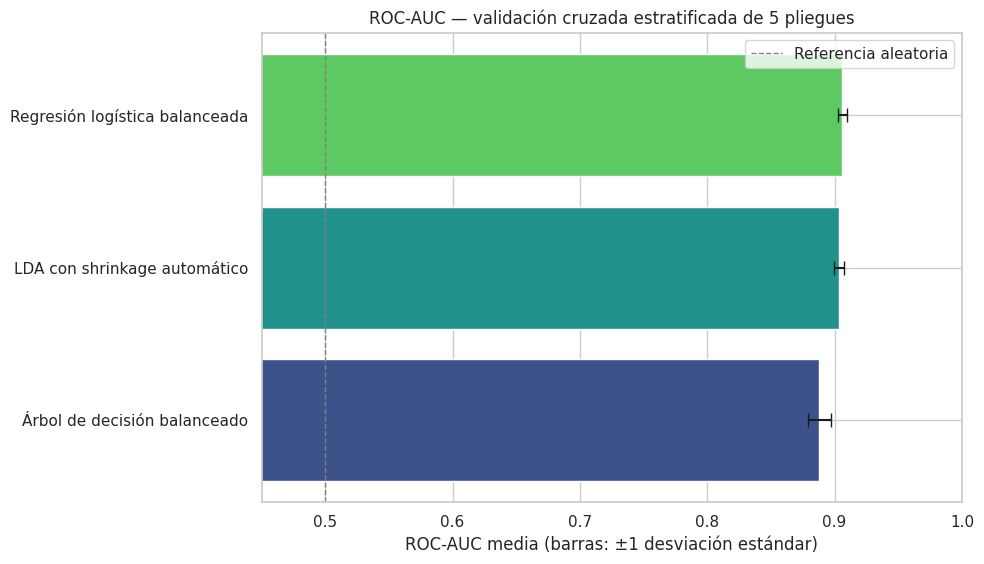

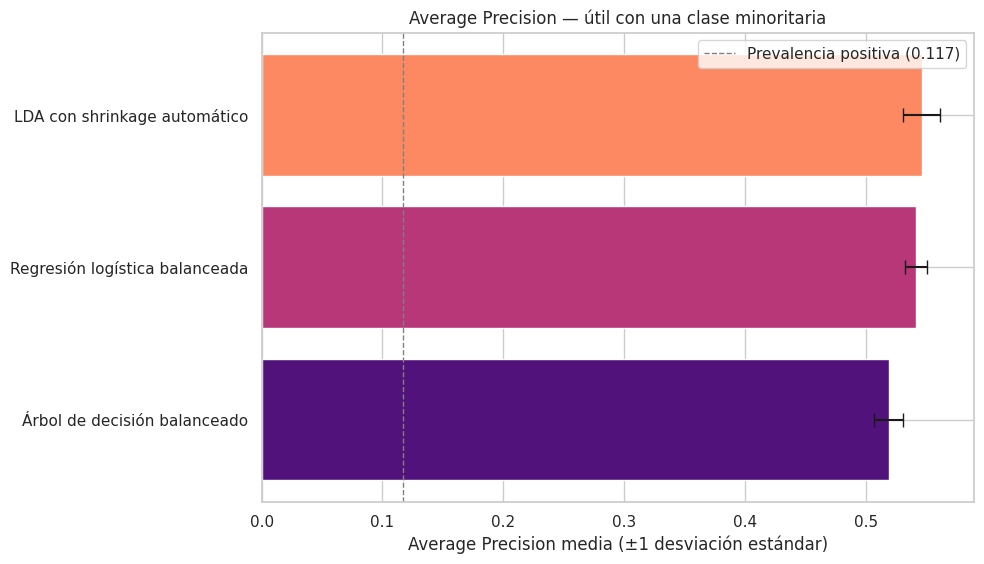

In [ ]:
sns.set_theme(style='whitegrid', context='notebook')
orden = resultados.sort_values('auc_media')
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(orden.modelo, orden.auc_media, xerr=orden.auc_sd,
        color=sns.color_palette('viridis', len(orden)), capsize=5)
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1, label='Referencia aleatoria')
ax.set_xlim(0.45, 1.0)
ax.set_xlabel('ROC-AUC media (barras: ±1 desviación estándar)')
ax.set_title('ROC-AUC — validación cruzada estratificada de 5 pliegues')
ax.legend()
plt.tight_layout()
plt.show()

orden_ap = resultados.sort_values('average_precision_media')
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(orden_ap.modelo, orden_ap.average_precision_media,
        xerr=orden_ap.average_precision_sd,
        color=sns.color_palette('magma', len(orden_ap)), capsize=5)
ax.axvline(y.mean(), color='gray', linestyle='--', linewidth=1,
           label=f'Prevalencia positiva ({y.mean():.3f})')
ax.set_xlabel('Average Precision media (±1 desviación estándar)')
ax.set_title('Average Precision — útil con una clase minoritaria')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Lectura de la corrida incluida y recomendación preliminar

En esta comparación, la regresión logística balanceada conserva el mejor AUC de los tres candidatos. LDA queda muy cerca en AUC y ofrece una formulación estadística distinta; el árbol de decisión ofrece reglas más intuitivas, pero su desempeño depende de la profundidad y puede perder capacidad de ordenamiento.

La recomendación es **usar la regresión logística balanceada como candidata principal para Kaggle**, con LDA y árbol de decisión como comparadores vistos en clase.

La tabla siguiente recoge los valores de la corrida reproducible con los archivos del grupo. Los resultados pueden variar levemente con la versión de scikit-learn o la configuración de ejecución.

In [ ]:
# Tabla de la corrida incluida; al ejecutar la sección 4 se recalcula `resultados`.
cols = ['modelo', 'auc_media', 'auc_sd', 'average_precision_media',
        'precision_media', 'recall_media', 'f1_media', 'balanced_accuracy_media']
display(resultados[cols].round(4))

,modelo,auc_media,auc_sd,average_precision_media,precision_media,recall_media,f1_media,balanced_accuracy_media
0,Regresión logística balanceada,0.9061,0.0037,0.5411,0.4102,0.8136,0.5453,0.8294
1,LDA con shrinkage automático,0.9034,0.0042,0.5458,0.6029,0.4276,0.5003,0.6952
2,Árbol de decisión balanceado,0.8881,0.0091,0.5185,0.3751,0.8483,0.5199,0.8304


### ROC-AUC de los tres candidatos

In [ ]:
# Gráfica incluida para consulta inmediata; se regenera en la sección 5.

### Average Precision de los tres candidatos

In [ ]:
# Gráfica incluida para consulta inmediata; se regenera en la sección 5.